# VGSP Quick Start — InSDN DDoS Detection

A minimal example of **Variance-Guided Scalar Projection (VGSP)**, a supervised, scikit-learn-compatible transformer that converts multidimensional numeric traffic data into **one scalar feature**.

This notebook uses the public [`vgsp`](https://pypi.org/project/vgsp/) package and a Decision Tree classifier. It preserves the research evaluation protocol: **stratified 80:20 development/test split** and optional **5-fold `StratifiedKFold` on development data only**. All imputation, scaling, CVR ranking, feature selection and projection weights are learned **only from training data**, through a scikit-learn `Pipeline`.

**Dataset:** Preprocessed binary InSDN CSV (`Label`: `0` = Normal, `1` = DDoS). The CSV is **not included** in the PyPI package or this notebook. The feature count `k=7` follows the selected configuration of the VGSP research notebook v4; it is not assumed optimal for other datasets.

**Source:** [VGSP GitHub](https://github.com/nqmn/vgsp) · [Research code archive](https://doi.org/10.5281/zenodo.24183611)

## 1. Install the package

Run this cell once in Jupyter or Google Colab. The first command installs **VGSP** from PyPI; the second installs the data-display and plotting libraries used in this example.

In [1]:
!pip install vgsp


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries and load the InSDN CSV

Download or prepare `insdn_ddos_binary_0n1d.csv`, then place it in one of the locations below (or edit `CSV_PATH`). In Google Colab, upload the CSV using the **Files** panel, and the filename in the notebook working directory will be found automatically.

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from vgsp import VGSP
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix,
)

# Edit this path if your dataset is somewhere else.
CANDIDATE_PATHS = [
    Path("../ds/insdn_ddos_binary_0n1d.csv"),
    Path("insdn_ddos_binary_0n1d.csv"),
]
CSV_PATH = next((p for p in CANDIDATE_PATHS if p.is_file()), None)

df = pd.read_csv(CSV_PATH, low_memory=False)
if "Label" not in df.columns:
    raise ValueError("Expected a binary target column named 'Label'.")

# The same identifier/metadata exclusions used by the research notebook.
metadata = [
    "src_ip", "dst_ip", "src_port", "dst_port", "timestamp",
    "Label_multi", "Attack_Type",
]
X = df.drop(columns=["Label"] + [c for c in metadata if c in df.columns])
y = df["Label"].astype(int)

non_numeric = X.select_dtypes(exclude="number").columns.tolist()
if non_numeric:
    raise ValueError(f"Non-numeric feature columns: {non_numeric}. Prepare numeric features first.")
if set(y.unique()) != {0, 1}:
    raise ValueError("Expected exactly two labels: 0 (Normal) and 1 (DDoS).")

print(f"CSV: {CSV_PATH}")
print(f"Samples: {len(X):,} | Input features: {X.shape[1]}")
print("Class counts (0=Normal, 1=DDoS):", y.value_counts().sort_index().to_dict())

CSV: ..\ds\insdn_ddos_binary_0n1d.csv
Samples: 190,366 | Input features: 77
Class counts (0=Normal, 1=DDoS): {0: 68424, 1: 121942}


## 3. Stratified 80:20 split and VGSP pipeline

VGSP is **supervised**, so `fit(X, y)` requires labels. The `Pipeline` guarantees that VGSP is fitted using only the development/training partition, not the held-out test partition.

In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

model = Pipeline([
    ("vgsp", VGSP(n_features=7, epsilon=1e-10)),
    ("dt", DecisionTreeClassifier(random_state=42)),
])

print(f"Development: {len(X_dev):,} records")
print(f"Held-out test: {len(X_test):,} records")

Development: 152,292 records
Held-out test: 38,074 records


## 4. Development-only cross-validation (5 folds)

Within each fold, the entire VGSP transformer and classifier are fitted **again on that fold's training data**. The held-out 20% test data is not used in cross-validation or parameter selection.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    model,
    X_dev,
    y_dev,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    n_jobs=1,
)
print(f"CV accuracy : {cv_results['test_accuracy'].mean():.6f} ± "
      f"{cv_results['test_accuracy'].std():.6f}")
print(f"CV Macro-F1 : {cv_results['test_f1_macro'].mean():.6f} ± "
      f"{cv_results['test_f1_macro'].std():.6f}")

CV accuracy : 0.999947 ± 0.000026
CV Macro-F1 : 0.999943 ± 0.000029


## 5. Fit on development data and evaluate the untouched test set

ROC-AUC and PR-AUC use continuous scores from `predict_proba`, **not** hard-label predictions. These metrics describe this example run and do not establish deployment latency or cross-dataset generalization.

In [6]:
model.fit(X_dev, y_dev)
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

results = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (DDoS)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Recall (DDoS)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "F1 (DDoS)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Macro-F1": f1_score(y_test, y_pred, average="macro"),
    "MCC": matthews_corrcoef(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_score),
    "PR-AUC (average precision)": average_precision_score(y_test, y_score),
})
print(results.round(6).to_string())
print("\nConfusion matrix [Normal (0), DDoS (1)]:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy                      0.999921
Precision (DDoS)              0.999877
Recall (DDoS)                 1.000000
F1 (DDoS)                     0.999939
Macro-F1                      0.999914
MCC                           0.999829
ROC-AUC                       0.999890
PR-AUC (average precision)    0.999877

Confusion matrix [Normal (0), DDoS (1)]:
[[13682     3]
 [    0 24389]]


## 6. Inspect selected features, CVR weights, and 1-D output

The fitted VGSP transformer exposes its selected feature names and CVR-derived projection weights. `transform()` applies the **frozen** mapping to test records without labels or re-estimation.

          Feature  CVR score  Projection weight
         Protocol   0.728136           0.290267
    Down/Up Ratio   0.536456           0.213855
Init Bwd Win Byts   0.336024           0.133954
      Pkt Len Min   0.287995           0.114808
     ACK Flag Cnt   0.216327           0.086237
  Bwd Pkt Len Min   0.202494           0.080723
       Bwd Pkts/s   0.201074           0.080157

Original test shape: (38074, 77) -> VGSP shape: (38074, 1)


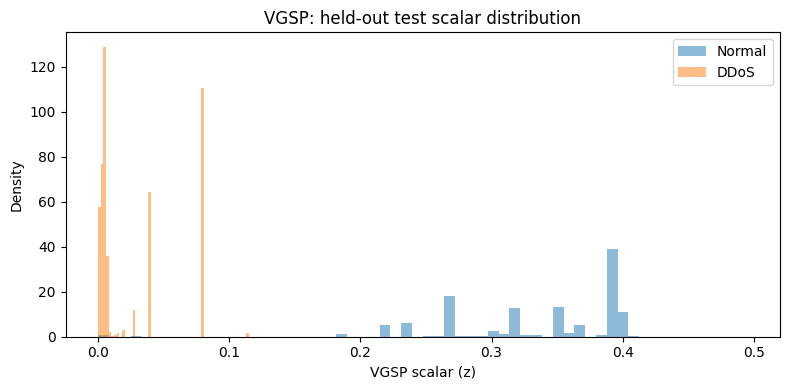

In [7]:
fitted_vgsp = model.named_steps["vgsp"]
selected = pd.DataFrame({
    "Feature": fitted_vgsp.selected_feature_names_,
    "CVR score": fitted_vgsp.cvr_scores_[fitted_vgsp.selected_indices_],
    "Projection weight": fitted_vgsp.weights_,
})
print(selected.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

Z_test = fitted_vgsp.transform(X_test)
print(f"\nOriginal test shape: {X_test.shape} -> VGSP shape: {Z_test.shape}")

# Optional visualization of the scalar distributions for each class.
fig, ax = plt.subplots(figsize=(8, 4))
for label, name in [(0, "Normal"), (1, "DDoS")]:
    ax.hist(Z_test[y_test.to_numpy() == label, 0], bins=60,
            density=True, alpha=0.5, label=name)
ax.set(title="VGSP: held-out test scalar distribution", xlabel="VGSP scalar (z)",
       ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

---

### Notes

- **No data leakage:** training-fitted imputation, variance filtering, min-max scaling, CVR estimation, and projection remain inside `VGSP.fit()` and `Pipeline`.
- **Scope:** this is a **within-dataset**, binary InSDN demonstration, not cross-dataset transfer or operational SDN deployment.
- **Reproducibility:** the research notebook v4 includes additional controls, analyses and experiments. This introductory notebook intentionally presents only the core library usage.
- **Dataset:** cite the original InSDN publication when using the dataset: Elsayed, Le-Khac & Jurcut (2020), *InSDN: A Novel SDN Intrusion Dataset*, IEEE Access. https://doi.org/10.1109/ACCESS.2020.3022633